# <span style="color:blue">COVID-19 Case Study</span>

In [1]:
import pandas as pd

### Data Loading

In [2]:
c19ds = r"covid_19_dataset-1718175635.xlsx"

conf = pd.read_excel(c19ds, sheet_name="covid_19_confirmed_v1")

recov = pd.read_excel(c19ds, sheet_name= "covid_19_recovered_v1")

death = pd.read_excel(c19ds, sheet_name= "covid_19_deaths_v1")

In [3]:
conf.head()

,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,5/20/21,5/21/21,5/22/21,5/23/21,5/24/21,5/25/21,5/26/21,5/27/21,5/28/21,5/29/21
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,64575,65080,65486,65728,66275,66903,67743,68366,69130,70111
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,132118,132153,132176,132209,132215,132229,132244,132264,132285,132297
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,126156,126434,126651,126860,127107,127361,127646,127926,128198,128456
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,13569,13569,13569,13569,13569,13664,13671,13682,13693,13693
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,31661,31909,32149,32441,32623,32933,33338,33607,33944,34180


In [4]:
recov.head()

,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,5/20/21,5/21/21,5/22/21,5/23/21,5/24/21,5/25/21,5/26/21,5/27/21,5/28/21,5/29/21
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,55687,55790,55889,56035,56295,56518,56711,56962,57119,57281
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,127869,128425,128601,128732,128826,128907,128978,129042,129097,129215
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,87902,88066,88208,88346,88497,88672,88861,89040,89232,89419
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,13234,13234,13234,13234,13234,13263,13381,13405,13416,13416
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,26483,26513,26775,26778,27087,27204,27467,27529,27577,27646


In [5]:
death.head()

,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,5/20/21,5/21/21,5/22/21,5/23/21,5/24/21,5/25/21,5/26/21,5/27/21,5/28/21,5/29/21
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,2772,2782,2792,2802,2812,2836,2855,2869,2881,2899
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,2440,2441,2442,2444,2445,2447,2447,2447,2448,2449
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,3401,3405,3411,3418,3426,3433,3440,3448,3455,3460
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,127,127,127,127,127,127,127,127,127,127
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,704,709,715,725,731,735,742,745,749,757


### Data Exploration (Knowing the structure of Data)

In [6]:
conf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 276 entries, 0 to 275
Columns: 498 entries, Province/State to 5/29/21
dtypes: float64(2), int64(494), object(2)
memory usage: 1.0+ MB


In [7]:
recov.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261 entries, 0 to 260
Columns: 498 entries, Province/State to 5/29/21
dtypes: float64(3), int64(493), object(2)
memory usage: 1015.6+ KB


In [8]:
death.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 276 entries, 0 to 275
Columns: 498 entries, Province/State to 5/29/21
dtypes: float64(3), int64(493), object(2)
memory usage: 1.0+ MB


* **Insight: The confirmed cases and deaths datasets contain 276 rows and 498 columns, while the recovered cases dataset contains 261 rows and 498 columns. Most columns are int64, with a few float64 and object columns representing location information and numerical COVID-19 data.**

### Confirmed cases over time for top Countries

In [9]:
conf["Country/Region"].value_counts().head(10)

Country/Region
China             34
Canada            16
France            12
United Kingdom    12
Australia          8
Netherlands        5
Denmark            3
Portugal           1
Oman               1
New Zealand        1
Name: count, dtype: int64

In [10]:
Latest_date = conf.columns[-1]
Latest_date

'5/29/21'

In [11]:
top_5 = (conf.groupby("Country/Region")[Latest_date].sum().sort_values(ascending=False).head())

In [12]:
top_5

Country/Region
US        33251939
India     27894800
Brazil    16471600
France     5719877
Turkey     5235978
Name: 5/29/21, dtype: int64

In [13]:
top_5_countries = top_5.index.tolist()

top_5_conf = conf[conf["Country/Region"].isin(top_5_countries)]

In [14]:
top_5_conf["Country/Region"].value_counts()

Country/Region
France    12
Brazil     1
India      1
Turkey     1
US         1
Name: count, dtype: int64

In [15]:
dates = pd.date_range("2020-01-22", "2021-05-29", periods=494)

print(dates.is_monotonic_increasing)
print(dates.min())
print(dates.max())

True
2020-01-22 00:00:00
2021-05-29 00:00:00


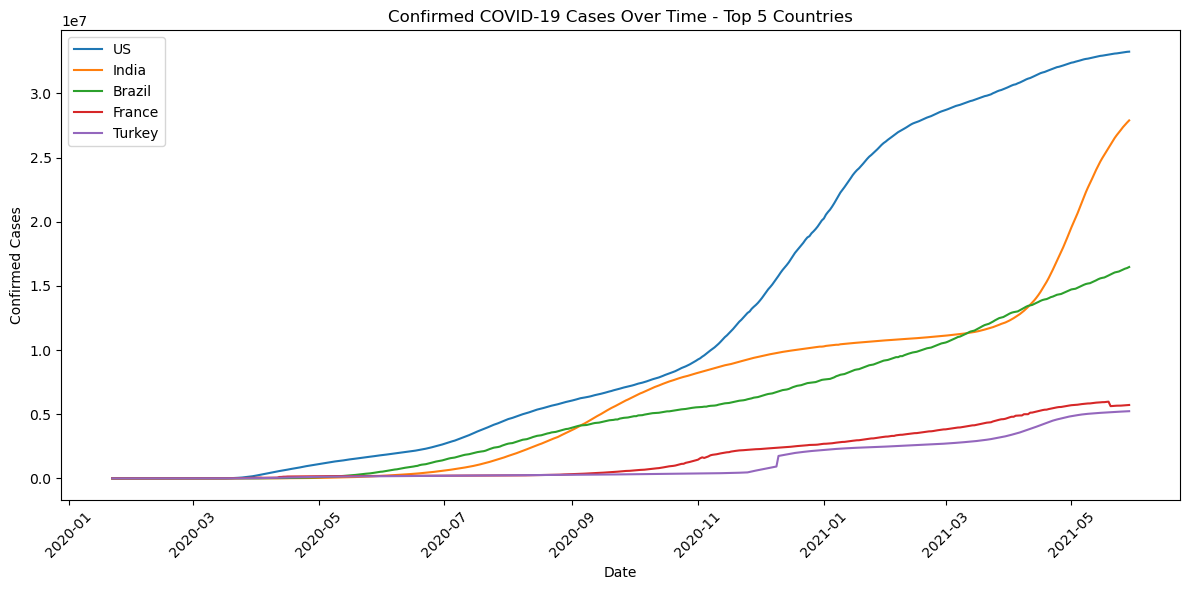

In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

for country in top_5_countries:
    country_data = top_5_conf[
        top_5_conf["Country/Region"] == country
    ]
    
    # Sum province-level rows for each date
    cases_over_time = country_data[conf.columns[4:]].sum()
    
    plt.plot(dates, cases_over_time, label=country)

plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.title("Confirmed COVID-19 Cases Over Time - Top 5 Countries")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

* **Insight: The US recorded the highest cumulative confirmed COVID-19 cases among the top 5 countries throughout most of the period. India and Brazil also showed substantial growth, with India experiencing a particularly sharp rise toward April–May 2021. France and Turkey remained considerably lower in comparison.**

### Confirmed cases over time for top China

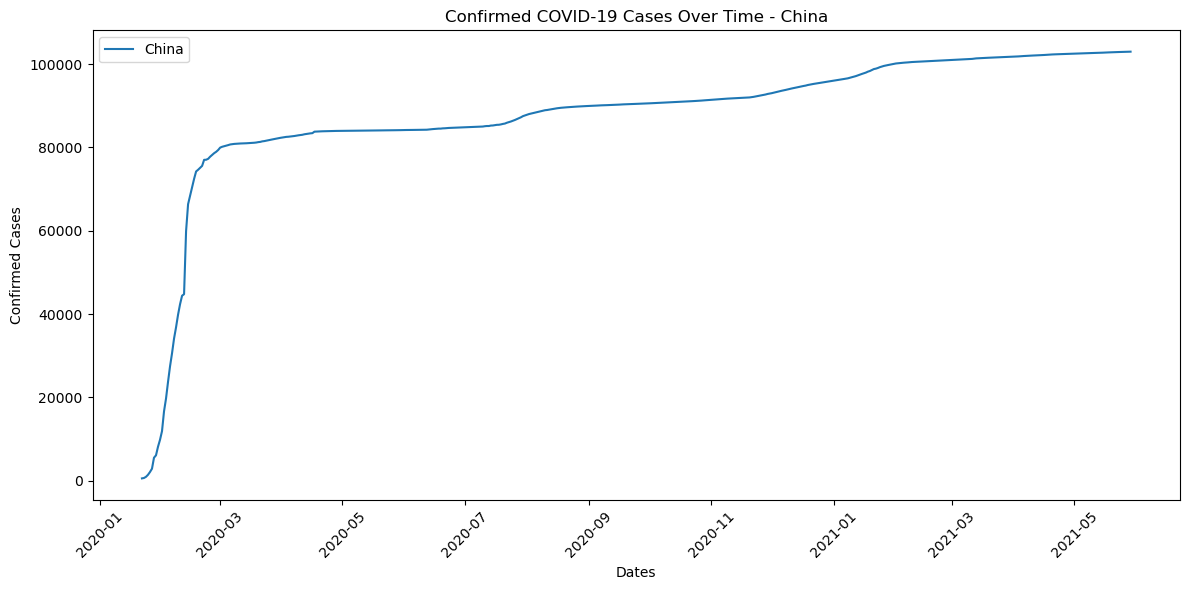

In [19]:
import matplotlib.pyplot as plt

china_data = conf[conf["Country/Region"]=="China"]

china_cases = china_data[conf.columns[4:]].sum()

plt.figure(figsize=(12,6))

plt.plot(dates, china_cases, label="China")

plt.xlabel("Dates")
plt.ylabel("Confirmed Cases")
plt.title("Confirmed COVID-19 Cases Over Time - China")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

* **Insight: China experienced a rapid rise in confirmed COVID-19 cases during January–February 2020. After the initial outbreak, the growth in cumulative cases slowed considerably, remaining relatively stable for most of the following period.**

### Handling missing data

In [20]:
print("Confirmed Cases - Missing Values:")
print(conf.isna().sum()[conf.isna().sum() > 0])

print("\nRecovered Cases - Missing Values:")
print(recov.isna().sum()[recov.isna().sum() > 0])

print("\nDeaths - Missing Values:")
print(death.isna().sum()[death.isna().sum() > 0])

Confirmed Cases - Missing Values:
Province/State    190
Lat                 2
Long                2
dtype: int64

Recovered Cases - Missing Values:
Province/State    191
Lat                 1
Long                1
4/20/20             1
dtype: int64

Deaths - Missing Values:
Province/State    190
Lat                 2
Long                2
4/20/20             1
dtype: int64


In [21]:
print("Deaths:")
print(death.loc[death["4/20/20"].isna(),["Country/Region", "4/19/20", "4/20/20", "4/21/20"]])

print("\nRecovered:")
print(recov.loc[recov["4/20/20"].isna(),["Country/Region", "4/19/20", "4/20/20", "4/21/20"]])

Deaths:
  Country/Region  4/19/20  4/20/20  4/21/20
2        Algeria      375      NaN      392

Recovered:
  Country/Region  4/19/20  4/20/20  4/21/20
6      Argentina      709      NaN      840


In [22]:
# Creating copies of Datasets 

conf_clean = conf.copy()
recov_clean = recov.copy()
death_clean = death.copy()

In [23]:
conf_clean.iloc[:, 4:] = conf_clean.iloc[:, 4:].ffill(axis = 1)

recov_clean.iloc[:, 4:] = recov_clean.iloc[:, 4:].ffill(axis = 1)

death_clean.iloc[:, 4:] = death_clean.iloc[:, 4:].ffill(axis = 1)

C:\Users\User\AppData\Local\Temp\ipykernel_11236\2689551170.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
256    0.0
257    0.0
258    0.0
259    0.0
260    0.0
Name: 1/22/20, Length: 261, dtype: float64' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  recov_clean.iloc[:, 4:] = recov_clean.iloc[:, 4:].ffill(axis = 1)
C:\Users\User\AppData\Local\Temp\ipykernel_11236\2689551170.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
256    0.0
257    0.0
258    0.0
259    0.0
260    0.0
Name: 1/23/20, Length: 261, dtype: float64' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  recov_clean.iloc[:, 4:] = recov_clean.iloc[:, 4:].ffill(ax

In [25]:
print("Recovered 4/20/20:", recov_clean.loc[6, "4/20/20"])
print("Deaths 4/20/20:", death_clean.loc[2, "4/20/20"])

Recovered 4/20/20: 709.0
Deaths 4/20/20: 375.0


In [26]:
print("Missing values in time-series columns:")

print("Confirmed:", conf_clean.iloc[:, 4:].isna().sum().sum())
print("Recovered:", recov_clean.iloc[:, 4:].isna().sum().sum())
print("Deaths:", death_clean.iloc[:, 4:].isna().sum().sum())

Missing values in time-series columns:
Confirmed: 0
Recovered: 0
Deaths: 0


### Data Cleaning & Preparation

In [27]:
conf_clean["Province/State"] = conf_clean["Province/State"].fillna("All Provinces")
recov_clean["Province/State"] = recov_clean["Province/State"].fillna("All Provinces")
death_clean["Province/State"] = death_clean["Province/State"].fillna("All Provinces")

In [28]:
print("Confirmed:", conf_clean["Province/State"].isna().sum())
print("Recovered:", recov_clean["Province/State"].isna().sum())
print("Deaths:", death_clean["Province/State"].isna().sum())

Confirmed: 0
Recovered: 0
Deaths: 0


### Peak Daily New Cases: Germany, France & Italy

In [29]:
countries = ["Germany", "France", "Italy"]

country_cases = (
    conf_clean[conf_clean["Country/Region"].isin(countries)].groupby("Country/Region")[conf_clean.columns[4:]].sum())

In [30]:
daily_new_cases = country_cases.diff(axis=1)

In [31]:
peak_daily_cases = daily_new_cases.max(axis=1)

print(peak_daily_cases)

Country/Region
France     117900.0
Germany     49044.0
Italy       40902.0
dtype: float64


In [37]:
for country in daily_new_cases.index:
    country_daily = pd.Series(
        daily_new_cases.loc[country].values,
        index = dates
    )

    print(country,"→", country_daily.idxmax().date(), "→", int(country_daily.max()))

France → 2021-04-11 → 117900
Germany → 2020-12-30 → 49044
Italy → 2020-11-13 → 40902


* **Insight: France recorded the highest peak in daily new confirmed cases (117,900) on 11-Apr-2021, substantially higher than Germany (49,044) and Italy (40,902). Germany and Italy reached their peaks earlier, in December and November 2020 respectively.**

### Comparison of Recovery Rates for Canada vs Australia as of December 31, 2020

In [39]:
countries1 = ["Canada", "Australia"]

confirmed_ca_au = (
    conf_clean[conf_clean["Country/Region"].isin(countries1)].groupby("Country/Region")[conf_clean.columns[4:]].sum())

recovered_ca_au = (
    recov_clean[recov_clean["Country/Region"].isin(countries1)].groupby("Country/Region")[recov_clean.columns[4:]].sum())

In [40]:
dec31_position = dates.get_loc("2020-12-31")

print(dec31_position)

344


In [42]:
confirmed_dec31 = confirmed_ca_au.iloc[:, dec31_position]
recovered_dec31 = recovered_ca_au.iloc[:, dec31_position]

print("Confirmed cases:")
print(confirmed_dec31)
print("\nRecovered cases:")
print(recovered_dec31)

Confirmed cases:
Country/Region
Australia     28425
Canada       584409
Name: 12/31/20, dtype: int64

Recovered cases:
Country/Region
Australia     22565.0
Canada       493638.0
Name: 12/31/20, dtype: float64


In [44]:
recovery_rate = (recovered_dec31 / confirmed_dec31) * 100

print("Recovery rate (%):")
print(recovery_rate.round(2))

Recovery rate (%):
Country/Region
Australia    79.38
Canada       84.47
Name: 12/31/20, dtype: float64


* **Insight: As of December 31, 2020, Canada had a higher recovery rate (84.47%) compared with Australia (79.38%), indicating that a larger proportion of Canada's confirmed cases had recovered by that date.**

### Death-rate distribution among Canadian provinces

In [45]:
canada_conf = conf_clean[conf_clean["Country/Region"] == "Canada"].copy()

canada_death = death_clean[death_clean["Country/Region"] == "Canada"].copy()

In [46]:
print(canada_conf["Province/State"].tolist())

['Alberta', 'British Columbia', 'Diamond Princess', 'Grand Princess', 'Manitoba', 'New Brunswick', 'Newfoundland and Labrador', 'Northwest Territories', 'Nova Scotia', 'Nunavut', 'Ontario', 'Prince Edward Island', 'Quebec', 'Repatriated Travellers', 'Saskatchewan', 'Yukon']


In [47]:
canada_provinces = ["Alberta", "British Columbia", "Manitoba", "New Brunswick", "Newfoundland and Labrador", "Northwest Territories", "Nova Scotia",
                    "Nunavut", "Ontario", "Prince Edward Island", "Quebec", "Saskatchewan", "Yukon"]

canada_conf_provinces = canada_conf[canada_conf["Province/State"].isin(canada_provinces)].copy()

canada_death_provinces = canada_death[canada_death["Province/State"].isin(canada_provinces)].copy()

In [49]:
print(canada_conf_provinces["Province/State"].tolist())
print("Number of provinces/territories:", len(canada_conf_provinces))

['Alberta', 'British Columbia', 'Manitoba', 'New Brunswick', 'Newfoundland and Labrador', 'Northwest Territories', 'Nova Scotia', 'Nunavut', 'Ontario', 'Prince Edward Island', 'Quebec', 'Saskatchewan', 'Yukon']
Number of provinces/territories: 13


In [50]:
latest_position = len(dates) - 1

print("Latest date:", dates[latest_position].date())

Latest date: 2021-05-29


In [52]:
canada_confirmed_latest = canada_conf_provinces.iloc[:, 4 + latest_position]
canada_deaths_latest = canada_death_provinces.iloc[:, 4 + latest_position]

print("Confirmed cases:")
print(canada_confirmed_latest)

print("\nDeaths:")
print(canada_deaths_latest)

Confirmed cases:
39    226855
40    143581
43     50499
44      2191
45      1302
46       127
47      5530
48       648
49    537138
50       200
51    369728
53     46464
54        84
Name: 5/29/21, dtype: int64

Deaths:
39     2214.0
40     1692.0
43     1045.0
44       43.0
45        6.0
46        0.0
47       84.0
48        4.0
49     8698.0
50        0.0
51    11125.0
53      537.0
54        2.0
Name: 5/29/21, dtype: float64


In [53]:
canada_death_rate = (canada_deaths_latest/canada_confirmed_latest)*100

canada_death_rate = canada_death_rate.round(2)

print(canada_death_rate)

39    0.98
40    1.18
43    2.07
44    1.96
45    0.46
46    0.00
47    1.52
48    0.62
49    1.62
50    0.00
51    3.01
53    1.16
54    2.38
Name: 5/29/21, dtype: float64


In [55]:
death_rate_table = pd.DataFrame({
    "Province/State": canada_conf_provinces["Province/State"].values,
    "Confirmed_cases": canada_confirmed_latest.values,
    "Deaths": canada_deaths_latest.values,
    "Death Rate (%)": canada_death_rate.values
})

print(death_rate_table)                                

               Province/State  Confirmed_cases   Deaths  Death Rate (%)
0                     Alberta           226855   2214.0            0.98
1            British Columbia           143581   1692.0            1.18
2                    Manitoba            50499   1045.0            2.07
3               New Brunswick             2191     43.0            1.96
4   Newfoundland and Labrador             1302      6.0            0.46
5       Northwest Territories              127      0.0            0.00
6                 Nova Scotia             5530     84.0            1.52
7                     Nunavut              648      4.0            0.62
8                     Ontario           537138   8698.0            1.62
9        Prince Edward Island              200      0.0            0.00
10                     Quebec           369728  11125.0            3.01
11               Saskatchewan            46464    537.0            1.16
12                      Yukon               84      2.0         

In [57]:
highest_rate = death_rate_table["Death Rate (%)"].max()
lowest_rate = death_rate_table["Death Rate (%)"].min()

highest = death_rate_table[
    death_rate_table["Death Rate (%)"]== highest_rate
]

lowest = death_rate_table[
    death_rate_table["Death Rate (%)"]== lowest_rate
] 

print("Highest Death Rate:")
print(highest)

print("\nLowest Death Rate:")
print(lowest)

Highest Death Rate:
   Province/State  Confirmed_cases   Deaths  Death Rate (%)
10         Quebec           369728  11125.0            3.01

Lowest Death Rate:
          Province/State  Confirmed_cases  Deaths  Death Rate (%)
5  Northwest Territories              127     0.0             0.0
9   Prince Edward Island              200     0.0             0.0


* **Insight: Among the Canadian provinces and territories, Quebec recorded the highest death rate at 3.01% as of 29-May-2021. Northwest Territories and Prince Edward Island had the lowest death rate at 0.00%, with no reported deaths in the dataset at that date.**

### Data Transformation

In [58]:
death_for_melt = death_clean.copy()

In [59]:
death_for_melt.columns = list(death_clean.columns[:4]) + list(dates)

In [60]:
death_long = death_for_melt.melt( 
    id_vars=["Province/State", "Country/Region", "Lat", "Long"], 
    var_name = "Date",
    value_name = "Deaths"
)

In [61]:
death_long["Date"] = pd.to_datetime(death_long["Date"])

In [62]:
print(death_long.shape)
print(death_long.head())
print(death_long.dtypes)

(136344, 6)
  Province/State Country/Region       Lat       Long       Date  Deaths
0  All Provinces    Afghanistan  33.93911  67.709953 2020-01-22     0.0
1  All Provinces        Albania  41.15330  20.168300 2020-01-22     0.0
2  All Provinces        Algeria  28.03390   1.659600 2020-01-22     0.0
3  All Provinces        Andorra  42.50630   1.521800 2020-01-22     0.0
4  All Provinces         Angola -11.20270  17.873900 2020-01-22     0.0
Province/State            object
Country/Region            object
Lat                      float64
Long                     float64
Date              datetime64[ns]
Deaths                   float64
dtype: object


### Total deaths per country

In [64]:
total_deaths_country = (death_long.groupby(["Country/Region", "Date"])["Deaths"].sum().reset_index())

In [65]:
latest_deaths_country = (total_deaths_country
    .sort_values("Date")
    .groupby("Country/Region")
    .tail(1).sort_values("Deaths", ascending=False)
    .reset_index(drop=True))

In [66]:
print(latest_deaths_country.head(10))
print(latest_deaths_country.shape)

   Country/Region       Date    Deaths
0              US 2021-05-29  594306.0
1          Brazil 2021-05-29  461057.0
2           India 2021-05-29  325972.0
3          Mexico 2021-05-29  223455.0
4  United Kingdom 2021-05-29  128037.0
5           Italy 2021-05-29  126002.0
6          Russia 2021-05-29  118781.0
7          France 2021-05-29  109518.0
8         Germany 2021-05-29   88413.0
9        Colombia 2021-05-29   87747.0
(193, 3)


### Top 5 countries by average daily deaths

In [68]:
daily_deaths = (
    death_long
    .groupby(["Country/Region", "Date"])["Deaths"]
    .sum()
    .reset_index()
)

In [69]:
daily_deaths["Daily New Deaths"] = (
    daily_deaths
    .groupby("Country/Region")["Deaths"]
    .diff()
)

In [70]:
print(daily_deaths.head(10))

  Country/Region       Date  Deaths  Daily New Deaths
0    Afghanistan 2020-01-22     0.0               NaN
1    Afghanistan 2020-01-23     0.0               0.0
2    Afghanistan 2020-01-24     0.0               0.0
3    Afghanistan 2020-01-25     0.0               0.0
4    Afghanistan 2020-01-26     0.0               0.0
5    Afghanistan 2020-01-27     0.0               0.0
6    Afghanistan 2020-01-28     0.0               0.0
7    Afghanistan 2020-01-29     0.0               0.0
8    Afghanistan 2020-01-30     0.0               0.0
9    Afghanistan 2020-01-31     0.0               0.0


In [72]:
avg_daily_deaths = (
    daily_deaths
    .groupby("Country/Region")["Daily New Deaths"]
    .mean()
)

In [73]:
print(avg_daily_deaths.head(10))

Country/Region
Afghanistan              5.880325
Albania                  4.967546
Algeria                  7.018256
Andorra                  0.257606
Angola                   1.535497
Antigua and Barbuda      0.085193
Argentina              156.405680
Armenia                  8.981744
Australia                1.845842
Austria                 21.484787
Name: Daily New Deaths, dtype: float64


In [74]:
top5_avg_deaths = (
    avg_daily_deaths
    .sort_values(ascending = False)
    .head()
)

In [75]:
print(top5_avg_deaths)

Country/Region
US                1205.488844
Brazil             935.206897
India              661.200811
Mexico             453.255578
United Kingdom     259.709939
Name: Daily New Deaths, dtype: float64


### Total deaths over time in the United States

In [76]:
us_deaths = daily_deaths[daily_deaths["Country/Region"] == "US"].copy()

In [77]:
print(us_deaths.head())
print(us_deaths.tail())

      Country/Region       Date  Deaths  Daily New Deaths
88426             US 2020-01-22     0.0               NaN
88427             US 2020-01-23     0.0               0.0
88428             US 2020-01-24     0.0               0.0
88429             US 2020-01-25     0.0               0.0
88430             US 2020-01-26     0.0               0.0
      Country/Region       Date    Deaths  Daily New Deaths
88915             US 2021-05-25  590941.0             621.0
88916             US 2021-05-26  591950.0            1009.0
88917             US 2021-05-27  593288.0            1338.0
88918             US 2021-05-28  593963.0             675.0
88919             US 2021-05-29  594306.0             343.0


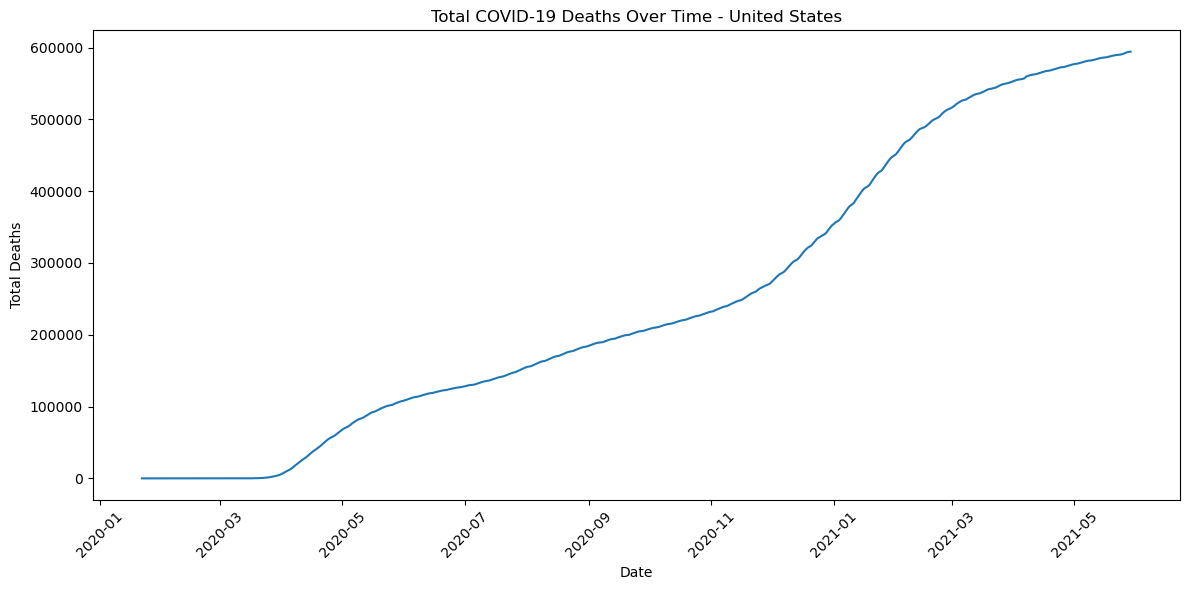

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(us_deaths["Date"], us_deaths["Deaths"])

plt.xlabel("Date")
plt.ylabel("Total Deaths")
plt.title("Total COVID-19 Deaths Over Time - United States")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Data Merging

In [81]:
conf_for_melt = conf_clean.copy()

conf_for_melt.columns = list(conf_clean.columns[:4]) + list(dates)

conf_long = conf_for_melt.melt(
    id_vars = ["Province/State", "Country/Region", "Lat", "Long"],
    var_name = "Date",
    value_name = "Confirmed"
)

conf_long["Date"] = pd.to_datetime(conf_long["Date"])

In [83]:
recov_for_melt = recov_clean.copy()

recov_for_melt.columns = list(recov_clean.columns[:4]) + list(dates)

recov_long = recov_for_melt.melt(
    id_vars = ["Province/State", "Country/Region", "Lat", "Long"],
    var_name = "Date",
    value_name = "Recovered"
)

recov_long["Date"] = pd.to_datetime(recov_long["Date"])

In [84]:
print("Confirmed :", conf_long.shape)
print("Recovered :", recov_long.shape)

print("\nConfirmed :")
print(conf_long.head())

print("\nRecovered :")
print(recov_long.head())

Confirmed : (136344, 6)
Recovered : (128934, 6)

Confirmed :
  Province/State Country/Region       Lat       Long       Date  Confirmed
0  All Provinces    Afghanistan  33.93911  67.709953 2020-01-22          0
1  All Provinces        Albania  41.15330  20.168300 2020-01-22          0
2  All Provinces        Algeria  28.03390   1.659600 2020-01-22          0
3  All Provinces        Andorra  42.50630   1.521800 2020-01-22          0
4  All Provinces         Angola -11.20270  17.873900 2020-01-22          0

Recovered :
  Province/State Country/Region       Lat       Long       Date  Recovered
0  All Provinces    Afghanistan  33.93911  67.709953 2020-01-22        0.0
1  All Provinces        Albania  41.15330  20.168300 2020-01-22        0.0
2  All Provinces        Algeria  28.03390   1.659600 2020-01-22        0.0
3  All Provinces        Andorra  42.50630   1.521800 2020-01-22        0.0
4  All Provinces         Angola -11.20270  17.873900 2020-01-22        0.0


In [85]:
confirmed_country_date = (
    conf_long
    .groupby(["Country/Region", "Date"])["Confirmed"]
    .sum()
    .reset_index()
)

deaths_country_date = (
    death_long
    .groupby(["Country/Region", "Date"])["Deaths"]
    .sum()
    .reset_index()
)

recovered_country_date = (
    recov_long
    .groupby(["Country/Region", "Date"])["Recovered"]
    .sum()
    .reset_index()
)

In [87]:
print("Confirmed :", confirmed_country_date.shape)
print("Deaths :", deaths_country_date.shape)
print("Recovered :", recovered_country_date.shape)

print("\nConfirmed:")
print(confirmed_country_date.head())

print("\nDeaths:")
print(deaths_country_date.head())

print("\nRecovered:")
print(recovered_country_date.head())

Confirmed : (95342, 3)
Deaths : (95342, 3)
Recovered : (95342, 3)

Confirmed:
  Country/Region       Date  Confirmed
0    Afghanistan 2020-01-22          0
1    Afghanistan 2020-01-23          0
2    Afghanistan 2020-01-24          0
3    Afghanistan 2020-01-25          0
4    Afghanistan 2020-01-26          0

Deaths:
  Country/Region       Date  Deaths
0    Afghanistan 2020-01-22     0.0
1    Afghanistan 2020-01-23     0.0
2    Afghanistan 2020-01-24     0.0
3    Afghanistan 2020-01-25     0.0
4    Afghanistan 2020-01-26     0.0

Recovered:
  Country/Region       Date  Recovered
0    Afghanistan 2020-01-22        0.0
1    Afghanistan 2020-01-23        0.0
2    Afghanistan 2020-01-24        0.0
3    Afghanistan 2020-01-25        0.0
4    Afghanistan 2020-01-26        0.0


In [88]:
confirmed_deaths = pd.merge(
    confirmed_country_date,
    deaths_country_date,
    on = ["Country/Region", "Date"],
    how = "inner"
)

In [89]:
merged = pd.merge(
    confirmed_deaths,
    recovered_country_date,
    on = ["Country/Region", "Date"],
    how = "inner"
)

In [90]:
print(merged.shape)
print(merged.head())
print(merged.dtypes)

(95342, 5)
  Country/Region       Date  Confirmed  Deaths  Recovered
0    Afghanistan 2020-01-22          0     0.0        0.0
1    Afghanistan 2020-01-23          0     0.0        0.0
2    Afghanistan 2020-01-24          0     0.0        0.0
3    Afghanistan 2020-01-25          0     0.0        0.0
4    Afghanistan 2020-01-26          0     0.0        0.0
Country/Region            object
Date              datetime64[ns]
Confirmed                  int64
Deaths                   float64
Recovered                float64
dtype: object


### Monthly Analysis of Confirmed Cases, Deaths, and Recoveries

In [92]:
merged_monthly = merged.copy()

merged_monthly = merged_monthly.sort_values(
    ["Country/Region", "Date"]
)

# Daily changes for each Country
merged_monthly["Daily New Confirmed"] = (
    merged_monthly
    .groupby("Country/Region")["Confirmed"]
    .diff()
)

merged_monthly["Daily New Deaths"] = (
    merged_monthly
    .groupby("Country/Region")["Deaths"]
    .diff()
)

merged_monthly["Daily New Recovered"] = (
    merged_monthly
    .groupby("Country/Region")["Recovered"]
    .diff()
)

In [93]:
merged_monthly[
    [
        "Country/Region",
        "Date",
        "Confirmed",
        "Deaths",
        "Recovered",
        "Daily New Confirmed",
        "Daily New Deaths",
        "Daily New Recovered"
    ]
].head(10)

,Country/Region,Date,Confirmed,Deaths,Recovered,Daily New Confirmed,Daily New Deaths,Daily New Recovered
0,Afghanistan,2020-01-22,0,0.0,0.0,NaN,NaN,NaN
1,Afghanistan,2020-01-23,0,0.0,0.0,0.0,0.0,0.0
2,Afghanistan,2020-01-24,0,0.0,0.0,0.0,0.0,0.0
3,Afghanistan,2020-01-25,0,0.0,0.0,0.0,0.0,0.0
4,Afghanistan,2020-01-26,0,0.0,0.0,0.0,0.0,0.0
5,Afghanistan,2020-01-27,0,0.0,0.0,0.0,0.0,0.0
6,Afghanistan,2020-01-28,0,0.0,0.0,0.0,0.0,0.0
7,Afghanistan,2020-01-29,0,0.0,0.0,0.0,0.0,0.0
8,Afghanistan,2020-01-30,0,0.0,0.0,0.0,0.0,0.0
9,Afghanistan,2020-01-31,0,0.0,0.0,0.0,0.0,0.0


In [94]:
merged_monthly["Month"] = (
    merged_monthly["Date"].dt.to_period("M")
)

In [95]:
monthly_totals = (
    merged_monthly
    .groupby("Month")[
        [
            "Daily New Confirmed",
            "Daily New Deaths",
            "Daily New Recovered"
        ]
    ]
    .sum()
    .reset_index()
)

In [97]:
monthly_totals.head(10)

,Month,Daily New Confirmed,Daily New Deaths,Daily New Recovered
0,2020-01,9370.0,196.0,195.0
1,2020-02,76086.0,2729.0,39556.0
2,2020-03,789781.0,41586.0,138023.0
3,2020-04,2404056.0,192893.0,835829.0
4,2020-05,2908334.0,137621.0,1623475.0
5,2020-06,4269745.0,133145.0,2715403.0
6,2020-07,7146838.0,167330.0,5020122.0
7,2020-08,7904322.0,175570.0,6450785.0
8,2020-09,8502645.0,163905.0,6856486.0
9,2020-10,12130527.0,181802.0,7165419.0


In [98]:
monthly_totals.tail(5)

,Month,Daily New Confirmed,Daily New Deaths,Daily New Recovered
12,2021-01,19467762.0,411058.0,10046576.0
13,2021-02,11152382.0,297478.0,7339259.0
14,2021-03,14717951.0,282700.0,8700833.0
15,2021-04,22501784.0,364155.0,15117656.0
16,2021-05,18552080.0,353216.0,18903718.0


In [99]:
print(
    "Peak confirmed cases:",
    monthly_totals.loc[
        monthly_totals["Daily New Confirmed"].idxmax()
    ]
)

print(
    "Peak deaths:",
    monthly_totals.loc[
        monthly_totals["Daily New Deaths"].idxmax()
    ]
)

print(
    "Peak recoveries:",
    monthly_totals.loc[
        monthly_totals["Daily New Recovered"].idxmax()
    ]
)

Peak confirmed cases: Month                     2021-04
Daily New Confirmed    22501784.0
Daily New Deaths         364155.0
Daily New Recovered    15117656.0
Name: 15, dtype: object
Peak deaths: Month                     2021-01
Daily New Confirmed    19467762.0
Daily New Deaths         411058.0
Daily New Recovered    10046576.0
Name: 12, dtype: object
Peak recoveries: Month                     2021-05
Daily New Confirmed    18552080.0
Daily New Deaths         353216.0
Daily New Recovered    18903718.0
Name: 16, dtype: object


* **Insight: Monthly confirmed cases increased considerably throughout the study period, with major waves visible in 2020 and 2021. The highest monthly confirmed cases were recorded in April 2021, with approximately 22.50 million new cases. The highest monthly deaths occurred in January 2021, reaching approximately 411,058 deaths. Monthly recoveries peaked in May 2021, at approximately 18.90 million recoveries. The results indicate that the pandemic experienced multiple waves, with the most substantial increase in confirmed cases occurring during early 2021.**

### Monthly COVID-19 Analysis for the United States, Italy, and Brazil

In [100]:
selected_countries = ["US", "Italy", "Brazil"]

selected_monthly = merged_monthly[
    merged_monthly["Country/Region"].isin(selected_countries)].copy()

In [101]:
selected_monthly[
    [
        "Country/Region",
        "Date",
        "Daily New Confirmed",
        "Daily New Deaths",
        "Daily New Recovered"
    ]
    ].head(10)

,Country/Region,Date,Daily New Confirmed,Daily New Deaths,Daily New Recovered
11362,Brazil,2020-01-22,NaN,NaN,NaN
11363,Brazil,2020-01-23,0.0,0.0,0.0
11364,Brazil,2020-01-24,0.0,0.0,0.0
11365,Brazil,2020-01-25,0.0,0.0,0.0
11366,Brazil,2020-01-26,0.0,0.0,0.0
11367,Brazil,2020-01-27,0.0,0.0,0.0
11368,Brazil,2020-01-28,0.0,0.0,0.0
11369,Brazil,2020-01-29,0.0,0.0,0.0
11370,Brazil,2020-01-30,0.0,0.0,0.0
11371,Brazil,2020-01-31,0.0,0.0,0.0


In [102]:
selected_monthly["Country/Region"].unique()

array(['Brazil', 'Italy', 'US'], dtype=object)

In [104]:
selected_monthly["Month"] = (
    selected_monthly["Date"].dt.to_period("M")
)

In [107]:
country_monthly_totals = (
    selected_monthly
    .groupby(["Country/Region", "Month"])[
        [
            "Daily New Confirmed",
            "Daily New Deaths",
            "Daily New Recovered"
        ]
    ]
    .sum()
    .reset_index()
)

In [108]:
country_monthly_totals.head(10)

,Country/Region,Month,Daily New Confirmed,Daily New Deaths,Daily New Recovered
0,Brazil,2020-01,0.0,0.0,0.0
1,Brazil,2020-02,2.0,0.0,0.0
2,Brazil,2020-03,5715.0,201.0,127.0
3,Brazil,2020-04,81470.0,5805.0,35808.0
4,Brazil,2020-05,427662.0,23308.0,170620.0
5,Brazil,2020-06,887192.0,30280.0,581763.0
6,Brazil,2020-07,1260444.0,32881.0,1220536.0
7,Brazil,2020-08,1245787.0,28906.0,1259737.0
8,Brazil,2020-09,902663.0,22571.0,1006183.0
9,Brazil,2020-10,724670.0,15932.0,730387.0


In [109]:
country_monthly_totals

,Country/Region,Month,Daily New Confirmed,Daily New Deaths,Daily New Recovered
0,Brazil,2020-01,0.0,0.0,0.0
1,Brazil,2020-02,2.0,0.0,0.0
2,Brazil,2020-03,5715.0,201.0,127.0
3,Brazil,2020-04,81470.0,5805.0,35808.0
4,Brazil,2020-05,427662.0,23308.0,170620.0
5,Brazil,2020-06,887192.0,30280.0,581763.0
6,Brazil,2020-07,1260444.0,32881.0,1220536.0
7,Brazil,2020-08,1245787.0,28906.0,1259737.0
8,Brazil,2020-09,902663.0,22571.0,1006183.0
9,Brazil,2020-10,724670.0,15932.0,730387.0


In [115]:
country_monthly_totals[
    country_monthly_totals["Country/Region"].isin(
        ["US", "Italy", "Brazil"]
    )
].groupby("Country/Region").tail(5)

,Country/Region,Month,Daily New Confirmed,Daily New Deaths,Daily New Recovered
12,Brazil,2021-01,1528758.0,29555.0,1327529.0
13,Brazil,2021-02,1346528.0,30438.0,1205943.0
14,Brazil,2021-03,2197488.0,66573.0,1799055.0
15,Brazil,2021-04,1910264.0,82266.0,1810580.0
16,Brazil,2021-05,1812589.0,57276.0,1504273.0
29,Italy,2021-01,445866.0,14357.0,547437.0
30,Italy,2021-02,372233.0,9183.0,394651.0
31,Italy,2021-03,659634.0,11647.0,507846.0
32,Italy,2021-04,437754.0,11461.0,552531.0
33,Italy,2021-05,190402.0,5195.0,379511.0


In [114]:
merged_monthly[
    merged_monthly["Country/Region"].isin(
        ["US", "Italy", "Brazil"]
    )
][
    [
        "Country/Region",
        "Date",
        "Recovered",
        "Daily New Recovered"
    ]
].tail(20)

,Country/Region,Date,Recovered,Daily New Recovered
88900,US,2021-05-10,0.0,0.0
88901,US,2021-05-11,0.0,0.0
88902,US,2021-05-12,0.0,0.0
88903,US,2021-05-13,0.0,0.0
88904,US,2021-05-14,0.0,0.0
88905,US,2021-05-15,0.0,0.0
88906,US,2021-05-16,0.0,0.0
88907,US,2021-05-17,0.0,0.0
88908,US,2021-05-18,0.0,0.0
88909,US,2021-05-19,0.0,0.0


* **Data limitation: Recovery values for the United States are recorded as zero throughout the dataset. These values are treated as unavailable rather than as evidence of zero actual recoveries.**

In [112]:
for country in selected_countries:
    country_data = country_monthly_totals[
        country_monthly_totals["Country/Region"] == country
        ]
    print(f"\n{country}")
    print(
        "Peak confirmed cases:",
        country_data.loc[
            country_data["Daily New Confirmed"].idxmax()
            ]
    )
    print(
        "Peak deaths:",
        country_data.loc[
            country_data["Daily New Deaths"].idxmax()
            ]
    )
    print(
        "Peak recoveries:",
        country_data.loc[
            country_data["Daily New Recovered"].idxmax()
            ]
    )


US
Peak confirmed cases: Country/Region                US
Month                    2020-12
Daily New Confirmed    6429031.0
Daily New Deaths         81143.0
Daily New Recovered   -5146319.0
Name: 45, dtype: object
Peak deaths: Country/Region                US
Month                    2021-01
Daily New Confirmed    6147690.0
Daily New Deaths         97285.0
Daily New Recovered          0.0
Name: 46, dtype: object
Peak recoveries: Country/Region                US
Month                    2020-11
Daily New Confirmed    4504713.0
Daily New Deaths         39271.0
Daily New Recovered    1533841.0
Name: 44, dtype: object

Italy
Peak confirmed cases: Country/Region            Italy
Month                   2020-11
Daily New Confirmed    922124.0
Daily New Deaths        16958.0
Daily New Recovered    468081.0
Name: 27, dtype: object
Peak deaths: Country/Region            Italy
Month                   2020-12
Daily New Confirmed    505612.0
Daily New Deaths        18583.0
Daily New Recovered    

In [122]:
peak_summary = []

for country in selected_countries:
    country_data = country_monthly_totals[
        country_monthly_totals["Country/Region"] == country
    ]
    peak_confirmed = country_data.loc[
        country_data["Daily New Confirmed"].idxmax()
    ]

    peak_deaths = country_data.loc[
        country_data["Daily New Deaths"].idxmax()
    ]

    peak_recovered = country_data.loc[
        country_data["Daily New Recovered"].idxmax()
    ]

    peak_summary.append({
        "Country" : country,
        "Peak Confirmed Month" : peak_confirmed["Month"],
        "Peak Monthly Confirmed" : peak_confirmed["Daily New Confirmed"],
        "Peak Death Month" : peak_deaths["Month"],
        "Peak Monthly Deaths" : peak_deaths["Daily New Deaths"],
        "Peak Recovered Month" : peak_recovered["Month"],
        "Peak Monthly Recovered" : peak_recovered["Daily New Recovered"]
    })

peak_summary_df = pd.DataFrame(peak_summary)

peak_summary_df
    

,Country,Peak Confirmed Month,Peak Monthly Confirmed,Peak Death Month,Peak Monthly Deaths,Peak Recovered Month,Peak Monthly Recovered
0,US,2020-12,6429031.0,2021-01,97285.0,2020-11,1533841.0
1,Italy,2020-11,922124.0,2020-12,18583.0,2020-12,705604.0
2,Brazil,2021-03,2197488.0,2021-04,82266.0,2021-04,1810580.0


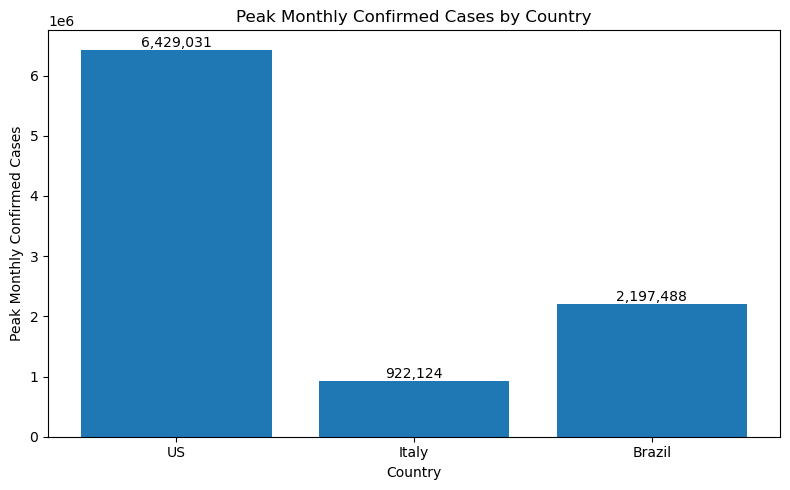

In [124]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    peak_summary_df["Country"],
    peak_summary_df["Peak Monthly Confirmed"]
)

plt.title("Peak Monthly Confirmed Cases by Country")
plt.xlabel("Country")
plt.ylabel("Peak Monthly Confirmed Cases")

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

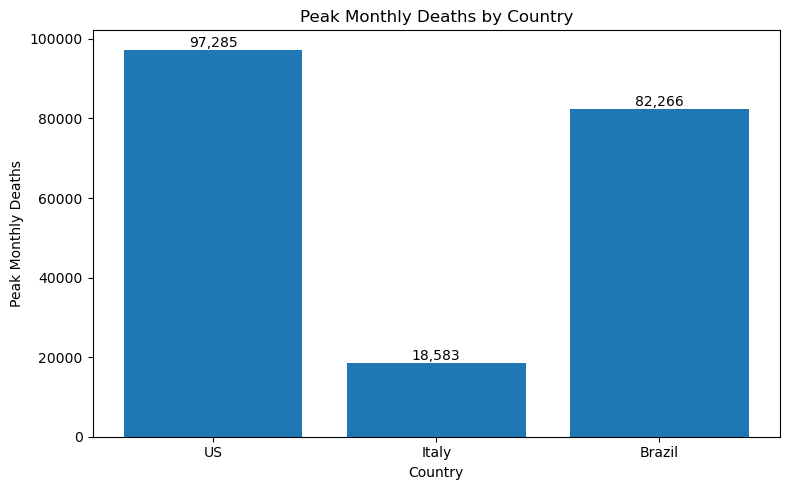

In [125]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    peak_summary_df["Country"],
    peak_summary_df["Peak Monthly Deaths"]
)

plt.title("Peak Monthly Deaths by Country")
plt.xlabel("Country")
plt.ylabel("Peak Monthly Deaths")

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

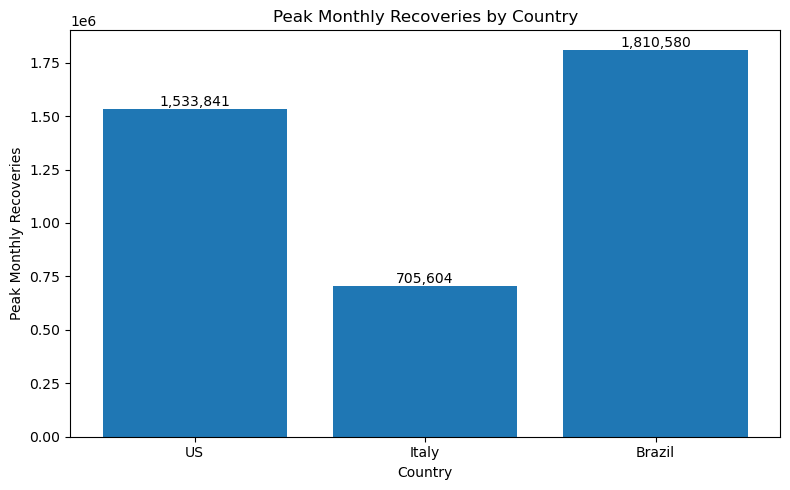

In [127]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    peak_summary_df["Country"],
    peak_summary_df["Peak Monthly Recovered"]
)

plt.title("Peak Monthly Recoveries by Country")
plt.xlabel("Country")
plt.ylabel("Peak Monthly Recoveries")

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

**Data-quality note: The US recovery series contains a reporting discontinuity on 14 December 2020, when cumulative recoveries dropped to zero. Therefore, the calculated US recovery peak should be interpreted cautiously. The original source values were retained unchanged.**

* **Insight: The peak months varied across countries and metrics. The US recorded its highest monthly confirmed cases in December 2020 and highest monthly deaths in January 2021. Italy reached its peak monthly confirmed cases in November 2020 and peak monthly deaths in December 2020. Brazil recorded its highest monthly confirmed cases in March 2021 and highest monthly deaths in April 2021. The recovery comparison should be interpreted cautiously because of a reporting discontinuity in the US cumulative recovery data.**

### Three countries with the highest average death rates during 2020

In [129]:
# Filtering data for year 2020
merged_2020 = merged[
    merged["Date"].dt.year == 2020
].copy()

# Calculating daily death rate.
merged_2020["Death Rate (%)"] = (
    merged_2020["Deaths"]  
    .div(merged_2020["Confirmed"])
    .mul(100)
    .fillna(0)
)

merged_2020.head()

,Country/Region,Date,Confirmed,Deaths,Recovered,Death Rate (%)
0,Afghanistan,2020-01-22,0,0.0,0.0,0.0
1,Afghanistan,2020-01-23,0,0.0,0.0,0.0
2,Afghanistan,2020-01-24,0,0.0,0.0,0.0
3,Afghanistan,2020-01-25,0,0.0,0.0,0.0
4,Afghanistan,2020-01-26,0,0.0,0.0,0.0


In [135]:
merged_2020[
    merged_2020["Death Rate (%)"] == float("inf")
][
    [
        "Country/Region",
        "Date",
        "Confirmed",
        "Deaths",
        "Death Rate (%)"
    ]
]

,Country/Region,Date,Confirmed,Deaths,Death Rate (%)
81561,Sudan,2020-03-13,0,1.0,inf


In [136]:
merged_2020["Death Rate (%)"] = (
    merged_2020["Death Rate (%)"]
    .replace([float("inf"), -float("inf")], float("nan"))
)

In [137]:
country_avg_death_rate = (
    merged_2020
    .groupby("Country/Region")["Death Rate (%)"]
    .mean()
    .reset_index()
    .rename(columns={"Death Rate (%)": "Average Death Rate (%)"})
)

In [138]:
top_3_death_rate = (
    country_avg_death_rate
    .sort_values(
        by="Average Death Rate (%)",
        ascending=False
    )
    .head(3)
    .reset_index(drop=True)
)

top_3_death_rate

,Country/Region,Average Death Rate (%)
0,Yemen,19.239250
1,MS Zaandam,17.713366
2,Italy,9.464157


In [142]:
# We are excluding "MS Zaandam" because it is a cruise ship, not a country.

country_avg_death_rate = country_avg_death_rate[
    country_avg_death_rate["Country/Region"] != "MS Zaandam"
]

In [141]:
top_3_death_rate = (
    country_avg_death_rate
    .sort_values(
        by="Average Death Rate (%)",
        ascending=False
    )
    .head(3)
    .reset_index(drop=True)
)

top_3_death_rate

,Country/Region,Average Death Rate (%)
0,Yemen,19.239250
1,Italy,9.464157
2,Sudan,8.833130


* **Insight: During 2020, Yemen recorded the highest average daily death rate at 19.24%, followed by Italy at 9.46% and Sudan at 8.83%.**

### South Africa: Recoveries vs Deaths

In [146]:
south_africa = merged[merged["Country/Region"] == "South Africa"].copy()

In [148]:
total_recoveries = south_africa["Recovered"].max()
total_deaths = south_africa["Deaths"].max()

print("Total Recoveries :", total_recoveries)
print("Total Deaths :", total_deaths)

Total Recoveries : 1554184.0
Total Deaths : 56363.0


In [149]:
recovery_death_ratio = total_recoveries/total_deaths

print("Recovery-To-Death Ratio :", recovery_death_ratio)

Recovery-To-Death Ratio : 27.57454358355659


* **Insight: South Africa recorded substantially more recoveries than deaths. Approximately 28 reported recoveries occurred for every 1 reported death, indicating that recoveries represented a much larger share of the reported COVID-19 outcomes in the dataset.**

### Monthly Recovery Ratio Analysis for the United States

In [150]:
us_data = merged[merged["Country/Region"] == "US"].copy()

In [151]:
us_data["Month"] = us_data["Date"].dt.to_period("M")

In [153]:
us_data[["Date", "Month"]].head()

,Date,Month
88426,2020-01-22,2020-01
88427,2020-01-23,2020-01
88428,2020-01-24,2020-01
88429,2020-01-25,2020-01
88430,2020-01-26,2020-01


In [154]:
us_data = us_data[
    (us_data["Date"] >= "2020-03-01") &
    (us_data["Date"] <= "2021-05-31")
].copy()

In [155]:
us_data["Month"].min(), us_data["Month"].max()

(Period('2020-03', 'M'), Period('2021-05', 'M'))

In [157]:
monthly_us = (
    us_data
    .sort_values("Date")
    .groupby("Month")
    .agg(
        Confirmed = ("Confirmed", "last"),
        Recovered = ("Recovered", "last")
    )
    .reset_index()
)

monthly_us

,Month,Confirmed,Recovered
0,2020-03,192301,7024.0
1,2020-04,1081020,153947.0
2,2020-05,1798718,444758.0
3,2020-06,2642174,720631.0
4,2020-07,4567420,1438160.0
5,2020-08,6026895,2184825.0
6,2020-09,7235428,2840688.0
7,2020-10,9165619,3612478.0
8,2020-11,13670332,5146319.0
9,2020-12,20099363,0.0


In [158]:
us_data[
    (us_data["Date"] >= "2020-12-01") &
    (us_data["Date"] <= "2021-01-31")
][["Date", "Confirmed", "Recovered"]].tail(20)

,Date,Confirmed,Recovered
88782,2021-01-12,22926246,0.0
88783,2021-01-13,23156608,0.0
88784,2021-01-14,23392315,0.0
88785,2021-01-15,23635046,0.0
88786,2021-01-16,23836726,0.0
88787,2021-01-17,24014508,0.0
88788,2021-01-18,24157924,0.0
88789,2021-01-19,24334630,0.0
88790,2021-01-20,24517866,0.0
88791,2021-01-21,24711684,0.0


In [159]:
us_data[us_data["Recovered"] > 0][
    ["Date", "Confirmed", "Recovered"]
].tail()

,Date,Confirmed,Recovered
88748,2020-12-09,15555949,5889896.0
88749,2020-12-10,15787464,5985047.0
88750,2020-12-11,16027441,6135314.0
88751,2020-12-12,16245026,6246605.0
88752,2020-12-13,16432729,6298082.0


In [160]:
monthly_us = (
    us_data
    .sort_values("Date")
    .groupby("Month")
    .agg(
        Confirmed=("Confirmed", "last"),
        Recovered=("Recovered", lambda x: x[x > 0].iloc[-1] if (x > 0).any() else float("nan"))
    )
    .reset_index()
)

monthly_us["Recovery Ratio (%)"] = (
    monthly_us["Recovered"] / monthly_us["Confirmed"] * 100
)

monthly_us

,Month,Confirmed,Recovered,Recovery Ratio (%)
0,2020-03,192301,7024.0,3.652607
1,2020-04,1081020,153947.0,14.240902
2,2020-05,1798718,444758.0,24.726388
3,2020-06,2642174,720631.0,27.274169
4,2020-07,4567420,1438160.0,31.487360
5,2020-08,6026895,2184825.0,36.251254
6,2020-09,7235428,2840688.0,39.260815
7,2020-10,9165619,3612478.0,39.413355
8,2020-11,13670332,5146319.0,37.645896
9,2020-12,20099363,6298082.0,31.334734


In [161]:
monthly_us.loc[
    monthly_us["Recovery Ratio (%)"].idxmax()
]

Month                   2020-10
Confirmed               9165619
Recovered             3612478.0
Recovery Ratio (%)    39.413355
Name: 7, dtype: object

* **Insight: October 2020 experienced the highest reported recovery ratio at 39.41%. The ratio increased from 3.65% in March to 39.41% in October, indicating that reported recoveries were accumulating relative to cumulative confirmed cases. The ratio subsequently declined in November and December. However, the US recovery data shows a reporting discontinuity from December 14, 2020 onward, with recoveries reported as zero, so the January–May 2021 ratios cannot be meaningfully interpreted. The high October ratio may reflect the accumulation of reported recoveries and reporting/timing effects rather than a single identifiable cause.**

-------------------------------------------------------------------------------------------------------------------------------------------------------

**Key Takeaways**

* Identified major trends in COVID-19 cases, recoveries, and deaths across countries and time periods.
* Compared mortality and recovery patterns across selected countries.
* Applied cumulative-data logic to perform accurate monthly analysis without double-counting.
* Identified and investigated inconsistencies in the US recovery data rather than blindly interpreting them.
* Used data validation and analytical reasoning to distinguish meaningful trends from reporting anomalies.

**Tools & Skills:** • Python • Pandas • Matplotlib • Data Cleaning • EDA • Time-Series Analysis • Data Aggregation • Data Validation • Data Visualization